In [1]:
%pip install -q yfinance


[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: /opt/miniconda3/bin/python -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


In [2]:
import os, warnings
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"    # hide TensorFlow startup logs
warnings.filterwarnings("ignore")           # hide library version warnings

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

In [4]:
# figure colors: actual data, AR, NN, reference lines
c_actual, c_ar, c_nn, c_ref = "#52514e", "#eb6834", "#2a78d6", "#898781"

plt.rcParams["figure.figsize"] = (10, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.color"] = "#e1e0d9"
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

In [5]:
tickers = ["AAPL", "AMZN", "GOOGL", "JNJ", "JPM", "KO", "MSFT", "NVDA", "WMT", "XOM"]

data = yf.download(tickers, start="2010-01-01", end="2026-11-21")


[                       0%                       ]


[**********            20%                       ]  2 of 10 completed


[**********            20%                       ]  2 of 10 completed


[*******************   40%                       ]  4 of 10 completed


[**********************50%                       ]  5 of 10 completed


[**********************60%****                   ]  6 of 10 completed


[**********************60%****                   ]  6 of 10 completed


[**********************60%****                   ]  6 of 10 completed


[**********************90%******************     ]  9 of 10 completed


[*********************100%***********************]  10 of 10 completed

In [6]:
close = data["Close"]
volume = data["Volume"]

In [7]:
close

Ticker,AAPL,AMZN,GOOGL,JNJ,JPM,KO,MSFT,NVDA,WMT,XOM
Date,,,,,,,,,,
2010-01-04,6.396099,6.695000,15.536592,39.778633,28.012632,17.103193,22.939926,0.422817,12.878362,36.903889
2010-01-05,6.407159,6.734500,15.468175,39.317379,28.555225,16.896297,22.947338,0.428992,12.750123,37.047974
2010-01-06,6.305243,6.612500,15.078241,39.637180,28.712120,16.890310,22.806511,0.431736,12.721627,37.368176
2010-01-07,6.293588,6.500000,14.727227,39.354275,29.280869,16.848326,22.569321,0.423275,12.728742,37.250767
2010-01-08,6.335430,6.676000,14.923556,39.489578,29.208971,16.536493,22.724981,0.424189,12.664625,37.101330
...,...,...,...,...,...,...,...,...,...,...
2026-11-16,352.779999,257.750000,283.720001,282.549988,338.209991,99.480003,516.991272,156.139999,128.410004,166.869995
2026-11-17,351.910004,257.890015,280.200012,278.700012,329.959991,98.790001,505.263947,155.460007,127.519997,167.210007
2026-11-18,352.450012,267.739990,282.440002,272.700012,324.109985,98.089996,507.309998,150.960007,127.360001,160.580002


In [8]:
volume

Ticker,AAPL,AMZN,GOOGL,JNJ,JPM,KO,MSFT,NVDA,WMT,XOM
Date,,,,,,,,,,
2010-01-04,493729600,151998000,78169752,9506200,35460500,13870400,38409100,800204000,62259300,27809100
2010-01-05,601904800,177038000,120067812,10673100,41208300,23172400,49749600,728648000,46945200,30174700
2010-01-06,552160000,143576000,158988852,13171500,27729000,19264600,58182400,649168000,37551600,35044700
2010-01-07,477131200,220604000,256315428,10901600,44864700,13234600,50559700,547792000,31988100,27192100
2010-01-08,447610800,196610000,188783028,7898000,33110100,28712400,51197400,478168000,34089600,24891800
...,...,...,...,...,...,...,...,...,...,...
2026-11-16,50292200,48054200,34747200,8101700,7250300,19154600,30218600,333822100,17780200,14286200
2026-11-17,37407500,38685200,32175900,8973500,8210200,19066200,27992800,406985100,19841300,11955200
2026-11-18,34209900,41289500,27401800,7935200,6778200,16554000,22050100,349791400,27962700,18122000


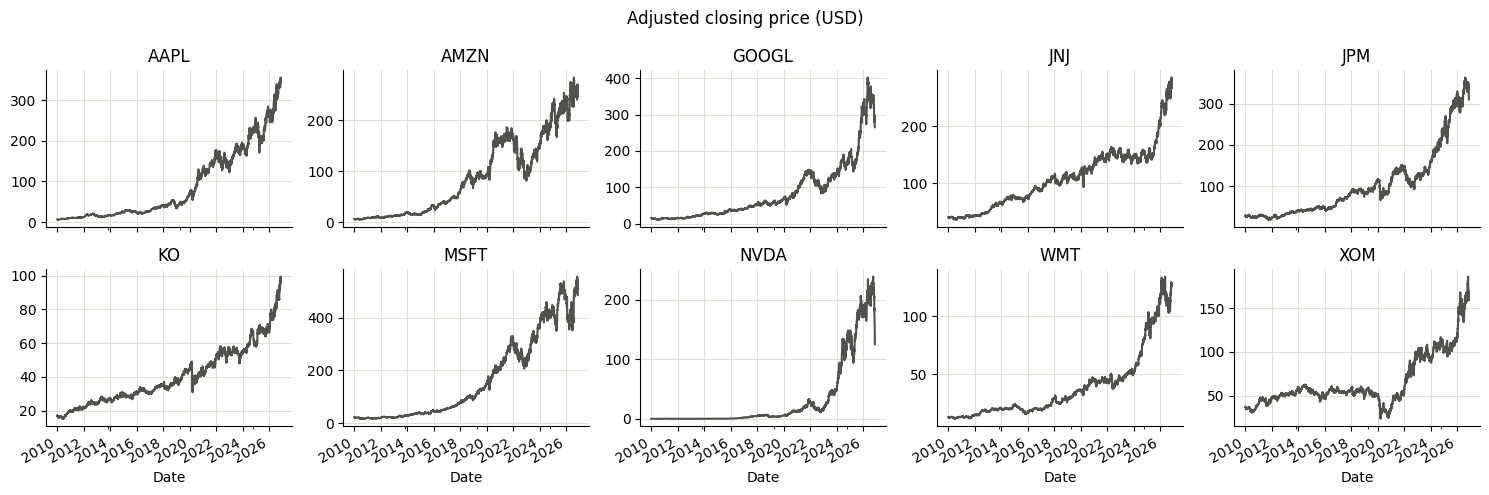

In [9]:
close.plot(subplots=True, layout=(2, 5), figsize=(15, 5), legend=False,
           title=tickers, color=c_actual)
plt.suptitle("Adjusted closing price (USD)")
plt.tight_layout()
plt.show()

### 2. Features

In [10]:
ret = close.pct_change().dropna()          # daily return
dvol = np.log(volume).diff().dropna()      # daily change in log volume

In [11]:
ret

Ticker,AAPL,AMZN,GOOGL,JNJ,JPM,KO,MSFT,NVDA,WMT,XOM
Date,,,,,,,,,,
2010-01-05,0.001729,0.005900,-0.004404,-0.011596,0.019370,-0.012097,0.000323,0.014603,-0.009958,0.003904
2010-01-06,-0.015907,-0.018116,-0.025209,0.008134,0.005494,-0.000354,-0.006137,0.006396,-0.002235,0.008643
2010-01-07,-0.001849,-0.017013,-0.023280,-0.007137,0.019809,-0.002486,-0.010400,-0.019598,0.000559,-0.003142
2010-01-08,0.006648,0.027077,0.013331,0.003438,-0.002455,-0.018508,0.006897,0.002161,-0.005037,-0.004012
2010-01-11,-0.008822,-0.024041,-0.001511,0.000156,-0.003358,0.020308,-0.012720,-0.014016,0.016502,0.011220
...,...,...,...,...,...,...,...,...,...,...
2026-11-16,-0.009796,-0.033413,-0.040741,-0.011199,-0.023051,0.002317,-0.011243,-0.041204,0.002498,-0.015632
2026-11-17,-0.002466,0.000543,-0.012407,-0.013626,-0.024393,-0.006936,-0.022684,-0.004355,-0.006931,0.002038
2026-11-18,0.001535,0.038194,0.007994,-0.021529,-0.017729,-0.007086,0.004049,-0.028946,-0.001255,-0.039651


In [12]:
dvol

Ticker,AAPL,AMZN,GOOGL,JNJ,JPM,KO,MSFT,NVDA,WMT,XOM
Date,,,,,,,,,,
2010-01-05,0.198111,0.152497,0.429174,0.115782,0.150220,0.513205,0.258708,-0.093676,-0.282327,0.081641
2010-01-06,-0.086261,-0.209500,0.280777,0.210329,-0.396161,-0.184693,0.156580,-0.115499,-0.223265,0.149621
2010-01-07,-0.146046,0.429505,0.477575,-0.189146,0.481172,-0.375435,-0.140428,-0.169796,-0.160352,-0.253698
2010-01-08,-0.063867,-0.115147,-0.305810,-0.322300,-0.303813,0.774494,0.012534,-0.135934,0.063628,-0.088388
2010-01-11,0.032138,-0.113082,0.423152,0.009790,-0.037900,-0.002441,0.294856,0.151906,0.207798,0.209236
...,...,...,...,...,...,...,...,...,...,...
2026-11-16,0.228283,0.433563,0.120630,0.254386,0.546244,0.060079,0.143111,-0.091469,0.066336,0.219149
2026-11-17,-0.295979,-0.216872,-0.076881,0.102202,0.124334,-0.004626,-0.076510,0.198168,0.109680,-0.178128
2026-11-18,-0.089356,0.065151,-0.160609,-0.122967,-0.191666,-0.141289,-0.238630,-0.151440,0.343106,0.415960


In [13]:
ret.describe().T

,count,mean,std,min,25%,50%,75%,max
Ticker,,,,,,,,
AAPL,4247.0,0.001094,0.017675,-0.128647,-0.007409,0.000998,0.010258,0.153288
AMZN,4247.0,0.001065,0.020778,-0.140494,-0.009232,0.000857,0.012047,0.157457
GOOGL,4247.0,0.000824,0.017671,-0.126412,-0.007753,0.000852,0.009555,0.162584
JNJ,4247.0,0.000510,0.010833,-0.100379,-0.004594,0.000393,0.005960,0.079977
JPM,4247.0,0.000715,0.017239,-0.149649,-0.007483,0.000701,0.009125,0.180125
KO,4247.0,0.000468,0.010834,-0.096725,-0.004744,0.000496,0.005952,0.064796
MSFT,4247.0,0.000853,0.016449,-0.147390,-0.007234,0.000683,0.009191,0.155067
NVDA,4247.0,0.001750,0.028689,-0.187559,-0.012680,0.001639,0.016308,0.298067
WMT,4247.0,0.000620,0.012626,-0.113758,-0.005338,0.000692,0.006598,0.117085


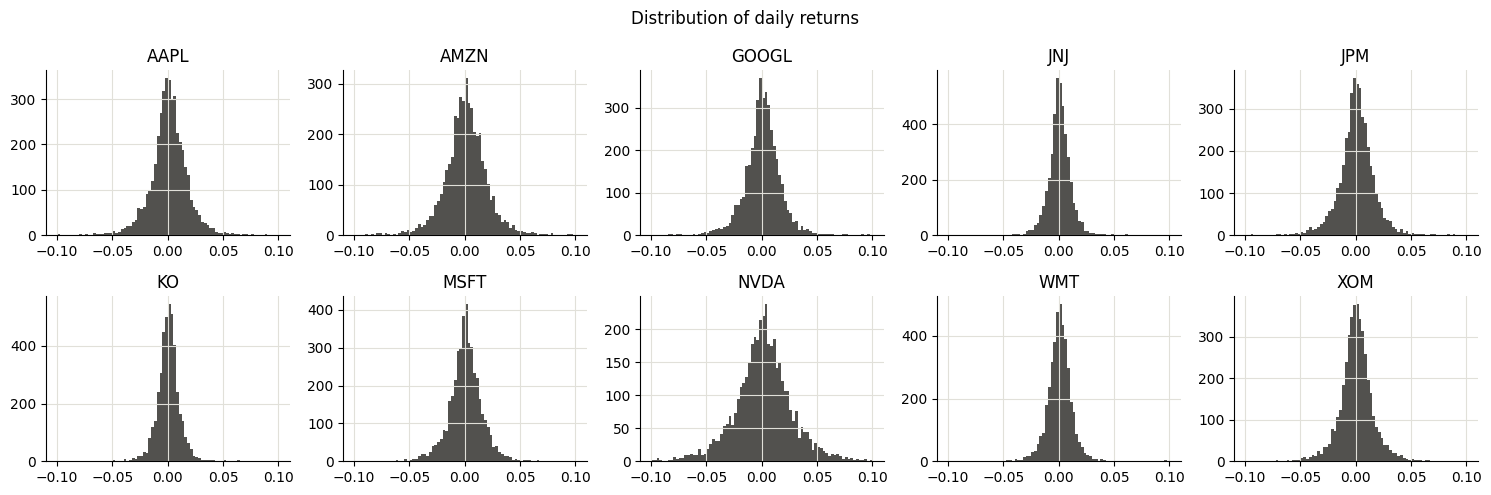

In [14]:
ret.hist(bins=80, range=(-0.1, 0.1), layout=(2, 5), figsize=(15, 5), color=c_actual)
plt.suptitle("Distribution of daily returns")
plt.tight_layout()
plt.show()

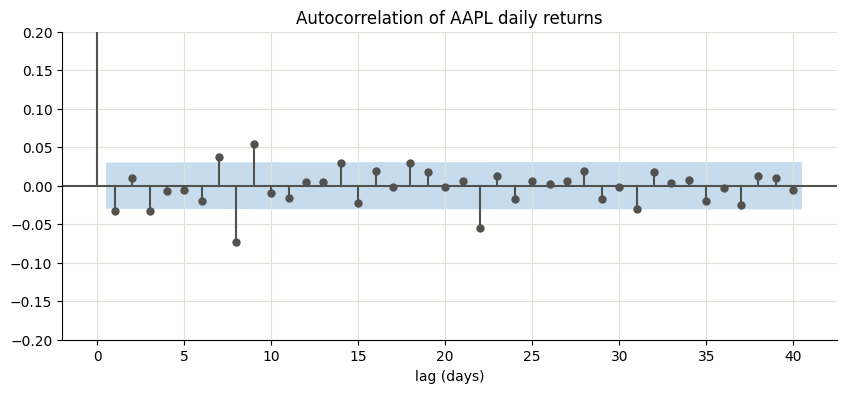

In [15]:
from statsmodels.graphics.tsaplots import plot_acf

plot_acf(ret["AAPL"], lags=40, color=c_actual, vlines_kwargs={"colors": c_actual},
         title="Autocorrelation of AAPL daily returns")
plt.xlabel("lag (days)")
plt.ylim(-0.2, 0.2)
plt.show()

### 3. Train, validation, and test sets

In [16]:
train_start, train_end = "2010-06-01", "2022-12-31"
val_start, val_end = "2023-01-01", "2023-12-31"
test_start, test_end = "2024-01-01", "2026-11-20"

In [17]:
# standardize with training-period statistics only
ret_mu, ret_sd = ret[:train_end].mean(), ret[:train_end].std()
dvol_mu, dvol_sd = dvol[:train_end].mean(), dvol[:train_end].std()

ret_z = (ret - ret_mu) / ret_sd
dvol_z = (dvol - dvol_mu) / dvol_sd

In [18]:
ret_z

Ticker,AAPL,AMZN,GOOGL,JNJ,JPM,KO,MSFT,NVDA,WMT,XOM
Date,,,,,,,,,,
2010-01-05,0.035944,0.235993,-0.298088,-1.138767,1.043668,-1.133202,-0.031694,0.467499,-0.846876,0.218093
2010-01-06,-0.938991,-0.918157,-1.519838,0.721880,0.271670,-0.070914,-0.426216,0.175273,-0.219082,0.514920
2010-01-07,-0.161842,-0.865179,-1.406546,-0.718326,1.068097,-0.263728,-0.686570,-0.750354,0.008062,-0.223289
2010-01-08,0.307877,1.253730,0.743348,0.279030,-0.170651,-1.713199,0.369779,0.024454,-0.446877,-0.277767
2010-01-11,-0.547320,-1.202938,-0.128249,-0.030507,-0.220853,1.798279,-0.828264,-0.551601,1.304035,0.676334
...,...,...,...,...,...,...,...,...,...,...
2026-11-16,-0.601186,-1.653342,-2.431948,-1.101337,-1.316562,0.170786,-0.738050,-1.519732,0.165692,-1.005693
2026-11-17,-0.195984,-0.021441,-0.768050,-1.330241,-1.391238,-0.666330,-1.436744,-0.207579,-0.600830,0.101159
2026-11-18,0.025176,1.788022,0.429955,-2.075533,-1.020479,-0.679872,0.195878,-1.083260,-0.139394,-2.510219


In [19]:
L = 60      # days of history in each sample

def make_windows(features, target, start, end):
    rows = target.index.get_indexer(target[start:end].index)    # row numbers of the days to predict
    X, y = [], []
    for t in tickers:
        values = np.column_stack([f[t] for f in features])
        for i in rows:
            X.append(values[i - L:i])        # the 60 days before day i
            y.append(target[t].iloc[i])      # the value on day i
    return np.array(X), np.array(y)

In [20]:
X_train, y_train = make_windows([ret_z, dvol_z], ret_z, train_start, train_end)
X_val, y_val = make_windows([ret_z, dvol_z], ret_z, val_start, val_end)
X_test, y_test = make_windows([ret_z, dvol_z], ret_z, test_start, test_end)

In [21]:
X_train.shape, X_val.shape, X_test.shape

((31700, 60, 2), (2500, 60, 2), (7260, 60, 2))

In [22]:
y_train.shape, y_val.shape, y_test.shape

((31700,), (2500,), (7260,))

In [23]:
# number of rows up to the end of each period
n_train = len(ret[:train_end])
n_val = len(ret[:val_end])
n_all = len(ret)

n_train, n_val, n_all

(3271, 3521, 4247)

In [24]:
test_days = ret.index[n_val:]

test_days

DatetimeIndex(['2024-01-02', '2024-01-03', '2024-01-04', '2024-01-05',
               '2024-01-08', '2024-01-09', '2024-01-10', '2024-01-11',
               '2024-01-12', '2024-01-16',
               ...
               '2026-11-09', '2026-11-10', '2026-11-11', '2026-11-12',
               '2026-11-13', '2026-11-16', '2026-11-17', '2026-11-18',
               '2026-11-19', '2026-11-20'],
              dtype='datetime64[s]', name='Date', length=726, freq=None)

### 4. Baseline

In [25]:
actual = ret[test_start:test_end]

mse_zero = (actual ** 2).mean()      # error of always predicting a return of zero

In [26]:
mse_zero

Ticker
AAPL     0.000298
AMZN     0.000426
GOOGL    0.000395
JNJ      0.000143
JPM      0.000225
KO       0.000112
MSFT     0.000289
NVDA     0.000941
WMT      0.000219
XOM      0.000224
dtype: float64

### 5. AR model

In [27]:
from statsmodels.tsa.ar_model import AutoReg

In [28]:
# try several orders: fit on the training period, score on the validation period
orders = [1, 2, 3, 5, 10, 20]
val_mse = pd.DataFrame(index=orders, columns=tickers, dtype=float)

for p in orders:
    for t in tickers:
        r = ret[t].to_numpy()
        res = AutoReg(r[:n_train], lags=p).fit()
        pred = res.apply(r[:n_val]).predict(start=n_train, end=n_val - 1)
        val_mse.loc[p, t] = ((r[n_train:n_val] - pred) ** 2).mean()

In [29]:
val_mse

,AAPL,AMZN,GOOGL,JNJ,JPM,KO,MSFT,NVDA,WMT,XOM
1,0.000164,0.000432,0.000368,0.000111,0.000170,0.000072,0.000253,0.000949,0.000097,0.000249
2,0.000164,0.000432,0.000368,0.000111,0.000168,0.000072,0.000253,0.000953,0.000097,0.000250
3,0.000165,0.000433,0.000368,0.000111,0.000167,0.000072,0.000253,0.000952,0.000097,0.000250
5,0.000165,0.000434,0.000367,0.000111,0.000167,0.000072,0.000254,0.000950,0.000097,0.000251
10,0.000167,0.000433,0.000368,0.000112,0.000168,0.000073,0.000252,0.000953,0.000098,0.000254
20,0.000169,0.000434,0.000368,0.000112,0.000170,0.000075,0.000252,0.000956,0.000102,0.000255


In [30]:
val_zero = (ret[val_start:val_end] ** 2).mean()
val_ratio = (val_mse / val_zero).mean(axis=1)      # below 1 beats predicting zero

In [31]:
val_ratio

1     0.999350
2     0.999007
3     0.998791
5     1.001273
10    1.006534
20    1.015903
dtype: float64

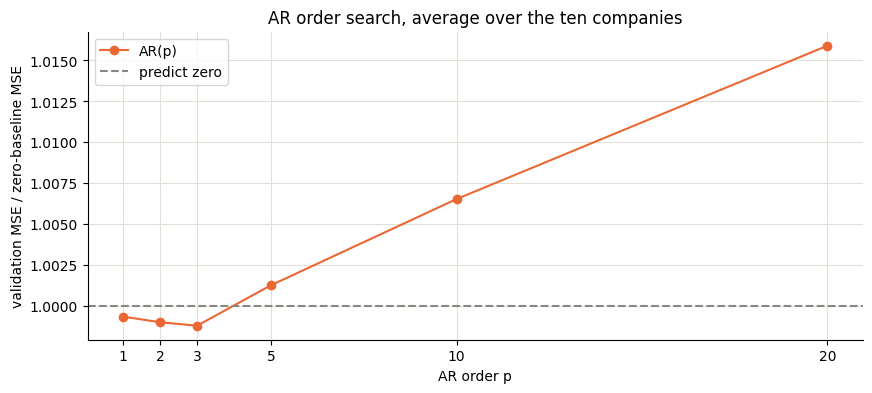

In [32]:
plt.plot(val_ratio, marker="o", color=c_ar, label="AR(p)")
plt.axhline(1.0, color=c_ref, linestyle="--", label="predict zero")
plt.xticks(orders)
plt.xlabel("AR order p")
plt.ylabel("validation MSE / zero-baseline MSE")
plt.title("AR order search, average over the ten companies")
plt.legend()
plt.show()

In [33]:
best_p = val_ratio.idxmin()

best_p

3

In [34]:
# final AR model: fit through the validation period, predict each test day one step ahead
pred_ar = pd.DataFrame(index=test_days, columns=tickers, dtype=float)
coef = pd.DataFrame(columns=tickers, dtype=float)

for t in tickers:
    r = ret[t].to_numpy()
    res = AutoReg(r[:n_val], lags=best_p).fit()
    pred_ar[t] = res.apply(r).predict(start=n_val, end=n_all - 1)
    coef[t] = res.params

In [35]:
pred_ar

,AAPL,AMZN,GOOGL,JNJ,JPM,KO,MSFT,NVDA,WMT,XOM
Date,,,,,,,,,,
2024-01-02,0.001436,0.001384,0.001118,0.000398,0.000960,0.000213,0.000809,0.001829,0.000392,0.000571
2024-01-03,0.002786,0.001523,0.001265,-0.001004,-0.000564,-0.000065,0.002500,0.003160,-0.000098,0.000538
2024-01-04,0.001806,0.001658,0.000672,0.000472,0.001747,0.000493,0.001259,0.001938,0.000486,0.000506
2024-01-05,0.002771,0.002080,0.001732,0.000498,-0.000408,-0.000094,0.002010,0.001527,0.000984,-0.000503
2024-01-08,0.001634,0.001433,0.000904,0.000107,0.000670,0.000299,0.001195,0.001029,0.000900,-0.000158
...,...,...,...,...,...,...,...,...,...,...
2026-11-16,0.000490,0.001535,0.000859,0.000166,-0.000397,-0.000538,0.001093,0.001623,-0.000400,-0.000235
2026-11-17,0.001679,0.001844,0.002095,0.001295,0.003370,0.000755,0.002224,0.004107,0.000308,-0.000098
2026-11-18,0.001248,0.001441,0.001444,0.001067,0.001431,-0.000126,0.003649,0.001557,0.000780,-0.000011


In [36]:
coef      # fitted AR coefficients: row 0 is the constant, row k is the weight on the return k days earlier

,AAPL,AMZN,GOOGL,JNJ,JPM,KO,MSFT,NVDA,WMT,XOM
0,0.001212,0.001166,0.000827,0.000453,0.000674,0.000416,0.001050,0.001828,0.000501,0.000406
1,-0.045195,-0.022460,-0.038997,-0.070976,-0.091740,-0.033778,-0.109918,-0.049769,-0.059139,-0.024029
2,-0.003085,-0.006911,0.000938,0.023051,0.055795,0.019293,-0.011195,0.018619,-0.000636,0.008293
3,-0.026883,-0.019401,-0.017419,-0.012067,-0.019780,-0.044202,-0.011902,-0.013878,-0.008558,-0.049900


### 6. Neural network

In [37]:
from tensorflow import keras
from tensorflow.keras import layers

keras.utils.set_random_seed(0)

In [38]:
model = keras.Sequential([
    keras.Input(shape=(60, 2)),
    layers.LSTM(64, return_sequences=True),
    layers.LSTM(32),
    layers.Dropout(0.2),
    layers.Dense(32, activation="relu"),
    layers.Dense(1),            # one output: predicted next-day return
])

In [39]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 60, 64)         │        17,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 30,657 (119.75 KB)

 Trainable params: 30,657 (119.75 KB)

 Non-trainable params: 0 (0.00 B)

In [40]:
model.compile(optimizer="adam", loss="mse")

stop = keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True)

In [41]:
history = model.fit(X_train, y_train, validation_data=(X_val, y_val),
                    epochs=30, batch_size=256, callbacks=[stop], verbose=2)

Epoch 1/30


124/124 - 4s - 31ms/step - loss: 1.0026 - val_loss: 0.8587


Epoch 2/30


124/124 - 2s - 18ms/step - loss: 1.0019 - val_loss: 0.8585


Epoch 3/30


124/124 - 2s - 18ms/step - loss: 1.0026 - val_loss: 0.8596


... (4 outputs left out)

Epoch 6/30


124/124 - 2s - 18ms/step - loss: 0.9953 - val_loss: 0.8656


Epoch 7/30


124/124 - 2s - 18ms/step - loss: 0.9916 - val_loss: 0.8655


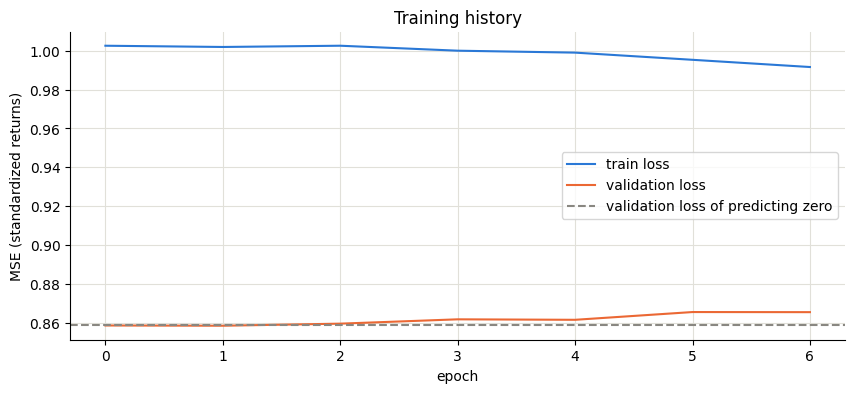

In [42]:
plt.plot(history.history["loss"], color=c_nn, label="train loss")
plt.plot(history.history["val_loss"], color=c_ar, label="validation loss")
plt.axhline((y_val ** 2).mean(), color=c_ref, linestyle="--", label="validation loss of predicting zero")
plt.xlabel("epoch")
plt.ylabel("MSE (standardized returns)")
plt.title("Training history")
plt.legend()
plt.show()

In [43]:
pred_nn = model.predict(X_test, verbose=0).reshape(len(tickers), -1).T
pred_nn = pd.DataFrame(pred_nn, index=test_days, columns=tickers)
pred_nn = pred_nn * ret_sd + ret_mu      # back to raw returns

In [44]:
pred_nn

,AAPL,AMZN,GOOGL,JNJ,JPM,KO,MSFT,NVDA,WMT,XOM
Date,,,,,,,,,,
2024-01-02,0.001966,0.001746,0.001305,0.000446,0.000448,0.000274,0.001025,0.001772,0.000389,0.001667
2024-01-03,0.002871,0.002269,0.001723,-0.000005,0.000221,-0.000091,0.001410,0.002774,0.000251,0.000767
2024-01-04,0.003626,0.002807,0.001682,-0.000219,0.000373,-0.000161,0.001706,0.003889,0.000327,0.000193
2024-01-05,0.003978,0.003905,0.002213,-0.000039,0.000386,0.000109,0.002108,0.003656,0.000751,0.000445
2024-01-08,0.003926,0.003772,0.002587,0.000169,0.000423,0.000458,0.002151,0.002309,0.001188,0.000626
...,...,...,...,...,...,...,...,...,...,...
2026-11-16,0.000648,0.001476,0.000328,0.000095,0.000578,-0.000106,0.002451,0.007063,0.000550,-0.000215
2026-11-17,0.001110,0.002628,0.002219,0.000421,0.001036,-0.000212,0.002643,0.008733,0.000285,0.000326
2026-11-18,0.001712,0.003168,0.003568,0.001133,0.002224,0.000089,0.003712,0.007639,0.000482,0.000668


### 7. Results

In [45]:
mse_ar = ((actual - pred_ar) ** 2).mean()
mse_nn = ((actual - pred_nn) ** 2).mean()

results = pd.DataFrame({"AR": mse_ar / mse_zero, "NN": mse_nn / mse_zero})

In [46]:
results      # test MSE divided by the zero-baseline MSE, below 1 beats the baseline

,AR,NN
Ticker,,
AAPL,0.999356,0.993237
AMZN,0.998970,0.998554
GOOGL,0.999509,1.000576
JNJ,1.002947,0.995333
JPM,1.000723,0.995342
KO,0.997230,0.995136
MSFT,1.019633,1.004535
NVDA,0.987238,0.996657
WMT,1.002760,0.993013


In [47]:
results.mean()

AR    1.000799
NN    0.997233
dtype: float64

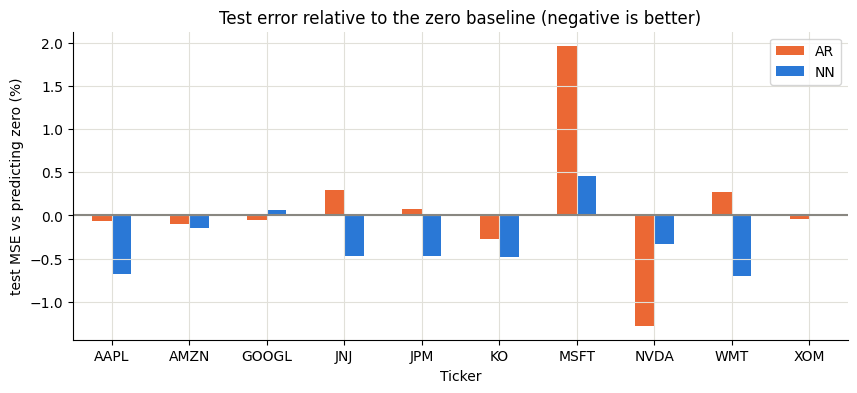

In [48]:
((results - 1) * 100).plot.bar(color=[c_ar, c_nn], figsize=(10, 4))
plt.axhline(0, color=c_ref)
plt.ylabel("test MSE vs predicting zero (%)")
plt.title("Test error relative to the zero baseline (negative is better)")
plt.xticks(rotation=0)
plt.show()

In [49]:
accuracy = pd.DataFrame({
    "always up": (actual > 0).mean(),
    "AR": (np.sign(pred_ar) == np.sign(actual)).mean(),
    "NN": (np.sign(pred_nn) == np.sign(actual)).mean(),
})

In [50]:
accuracy      # share of test days with the correct direction

,always up,AR,NN
AAPL,0.535813,0.517906,0.538567
AMZN,0.515152,0.516529,0.519284
GOOGL,0.539945,0.535813,0.539945
JNJ,0.538567,0.497245,0.524793
JPM,0.561983,0.555096,0.546832
KO,0.517906,0.512397,0.538567
MSFT,0.522039,0.513774,0.513774
NVDA,0.527548,0.533058,0.524793
WMT,0.544077,0.511019,0.530303
XOM,0.538567,0.500000,0.511019


In [51]:
accuracy.mean()

always up    0.534160
AR           0.519284
NN           0.528788
dtype: float64

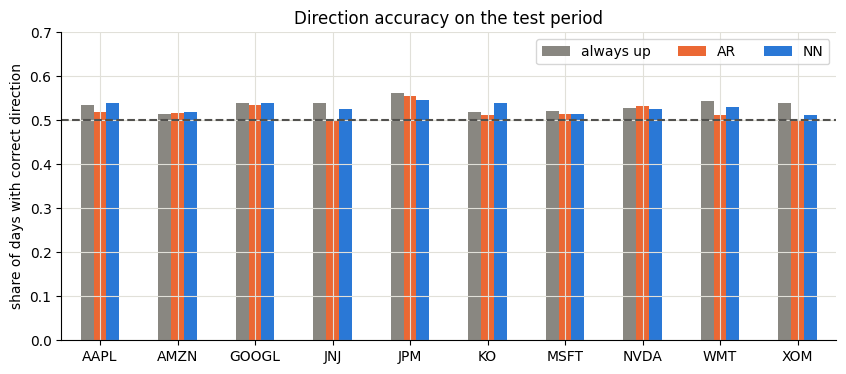

In [52]:
accuracy.plot.bar(color=[c_ref, c_ar, c_nn], figsize=(10, 4))
plt.axhline(0.5, color=c_actual, linestyle="--")
plt.ylim(0, 0.7)
plt.ylabel("share of days with correct direction")
plt.title("Direction accuracy on the test period")
plt.xticks(rotation=0)
plt.legend(ncol=3)
plt.show()

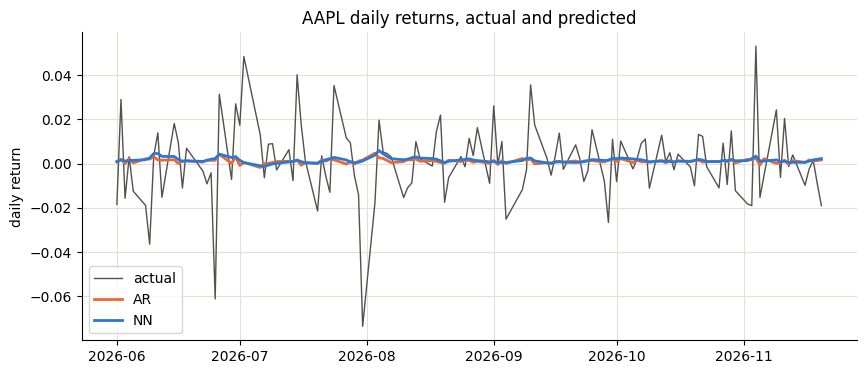

In [53]:
t = "AAPL"

plt.plot(actual[t]["2026-06-01":], color=c_actual, linewidth=1, label="actual")
plt.plot(pred_ar[t]["2026-06-01":], color=c_ar, linewidth=2, label="AR")
plt.plot(pred_nn[t]["2026-06-01":], color=c_nn, linewidth=2, label="NN")
plt.ylabel("daily return")
plt.title("AAPL daily returns, actual and predicted")
plt.legend()
plt.show()

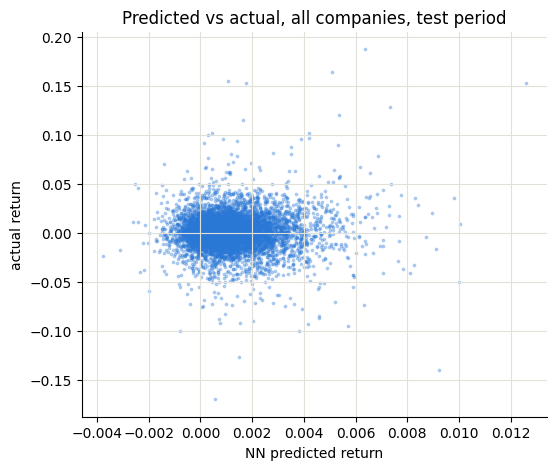

In [54]:
plt.figure(figsize=(6, 5))
plt.scatter(pred_nn.to_numpy().ravel(), actual.to_numpy().ravel(), s=3, alpha=0.3, color=c_nn)
plt.xlabel("NN predicted return")
plt.ylabel("actual return")
plt.title("Predicted vs actual, all companies, test period")
plt.show()

### 8. A second target, the next-day trading range

In [55]:
rng = ((data["High"] - data["Low"]) / close).loc[ret.index]      # daily high-low range as a share of the close

In [56]:
rng

Ticker,AAPL,AMZN,GOOGL,JNJ,JPM,KO,MSFT,NVDA,WMT,XOM
Date,,,,,,,,,,
2010-01-05,0.010915,0.027248,0.010096,0.012514,0.024267,0.015084,0.014858,0.028785,0.011548,0.009363
2010-01-06,0.021235,0.023289,0.032059,0.011016,0.017760,0.008166,0.018200,0.018538,0.007653,0.017995
2010-01-07,0.014009,0.027077,0.029204,0.009533,0.033713,0.011034,0.016749,0.026472,0.009142,0.009169
2010-01-08,0.013869,0.034826,0.023488,0.009812,0.013876,0.016138,0.020874,0.023181,0.009563,0.007624
2010-01-11,0.021655,0.027550,0.017335,0.011523,0.019762,0.029323,0.021143,0.038272,0.024719,0.012375
...,...,...,...,...,...,...,...,...,...,...
2026-11-16,0.016498,0.024210,0.039405,0.028030,0.029124,0.014877,0.021487,0.052453,0.015342,0.022772
2026-11-17,0.016169,0.022878,0.020093,0.014926,0.024700,0.010932,0.037788,0.050560,0.014586,0.019377
2026-11-18,0.014045,0.032793,0.018694,0.022516,0.019685,0.017433,0.018415,0.061606,0.021200,0.039918


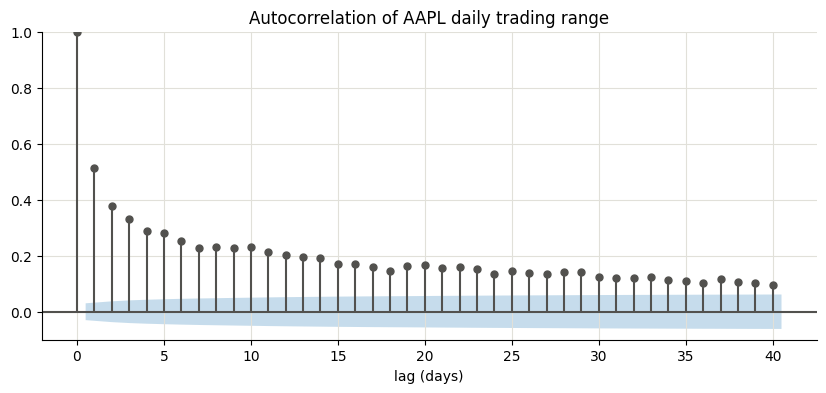

In [57]:
plot_acf(rng["AAPL"], lags=40, color=c_actual, vlines_kwargs={"colors": c_actual},
         title="Autocorrelation of AAPL daily trading range")
plt.xlabel("lag (days)")
plt.ylim(-0.1, 1)
plt.show()

In [58]:
rng_mu, rng_sd = rng[:train_end].mean(), rng[:train_end].std()

rng_z = (rng - rng_mu) / rng_sd

In [59]:
X_train_rng, y_train_rng = make_windows([ret_z, dvol_z, rng_z], rng_z, train_start, train_end)
X_val_rng, y_val_rng = make_windows([ret_z, dvol_z, rng_z], rng_z, val_start, val_end)
X_test_rng, y_test_rng = make_windows([ret_z, dvol_z, rng_z], rng_z, test_start, test_end)

In [60]:
X_train_rng.shape, X_val_rng.shape, X_test_rng.shape

((31700, 60, 3), (2500, 60, 3), (7260, 60, 3))

In [61]:
# baseline: predict the average range of the previous 20 days
pred_avg = rng.rolling(20).mean().shift(1)
err_avg = (rng - pred_avg) ** 2

val_avg = err_avg[val_start:val_end].mean()
mse_avg = err_avg[test_start:test_end].mean()

In [62]:
mse_avg

Ticker
AAPL     0.000133
AMZN     0.000131
GOOGL    0.000129
JNJ      0.000050
JPM      0.000103
KO       0.000038
MSFT     0.000081
NVDA     0.000342
WMT      0.000070
XOM      0.000074
dtype: float64

In [63]:
# AR order search: fit on the training period, score on the validation period
val_mse_rng = pd.DataFrame(index=orders, columns=tickers, dtype=float)

for p in orders:
    for t in tickers:
        r = rng[t].to_numpy()
        res = AutoReg(r[:n_train], lags=p).fit()
        pred = res.apply(r[:n_val]).predict(start=n_train, end=n_val - 1)
        val_mse_rng.loc[p, t] = ((r[n_train:n_val] - pred) ** 2).mean()

In [64]:
val_ratio_rng = (val_mse_rng / val_avg).mean(axis=1)      # below 1 beats the 20-day average

In [65]:
val_ratio_rng

1     1.092161
2     1.034635
3     1.008063
5     0.971056
10    0.968663
20    0.969064
dtype: float64

In [66]:
best_p_rng = val_ratio_rng.idxmin()

best_p_rng

10

In [67]:
pred_ar_rng = pd.DataFrame(index=test_days, columns=tickers, dtype=float)

for t in tickers:
    r = rng[t].to_numpy()
    res = AutoReg(r[:n_val], lags=best_p_rng).fit()
    pred_ar_rng[t] = res.apply(r).predict(start=n_val, end=n_all - 1)

In [68]:
pred_ar_rng

,AAPL,AMZN,GOOGL,JNJ,JPM,KO,MSFT,NVDA,WMT,XOM
Date,,,,,,,,,,
2024-01-02,0.013616,0.015847,0.013526,0.009541,0.011204,0.009241,0.010889,0.021664,0.009289,0.011771
2024-01-03,0.017715,0.020333,0.018226,0.016191,0.014839,0.012792,0.015644,0.026507,0.011559,0.015978
2024-01-04,0.014857,0.019029,0.016587,0.012998,0.013024,0.010870,0.014208,0.023105,0.010656,0.016698
2024-01-05,0.015088,0.021008,0.018317,0.012307,0.014509,0.010342,0.015489,0.025259,0.011632,0.019696
2024-01-08,0.015320,0.018624,0.016442,0.012327,0.013536,0.012488,0.015421,0.023765,0.013258,0.016303
...,...,...,...,...,...,...,...,...,...,...
2026-11-16,0.018883,0.026505,0.029693,0.020585,0.016225,0.014523,0.025343,0.057027,0.017828,0.020035
2026-11-17,0.019851,0.026641,0.031324,0.022474,0.023353,0.015119,0.023945,0.054798,0.017660,0.020143
2026-11-18,0.019466,0.026511,0.027017,0.019220,0.023344,0.014333,0.028531,0.054562,0.017317,0.021690


In [69]:
keras.utils.set_random_seed(0)

model_rng = keras.Sequential([
    keras.Input(shape=(60, 3)),
    layers.LSTM(64, return_sequences=True),
    layers.LSTM(32),
    layers.Dropout(0.2),
    layers.Dense(32, activation="relu"),
    layers.Dense(1),            # one output: predicted next-day range
])

In [70]:
model_rng.compile(optimizer="adam", loss="mse")

stop_rng = keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True)

In [71]:
history_rng = model_rng.fit(X_train_rng, y_train_rng, validation_data=(X_val_rng, y_val_rng),
                            epochs=30, batch_size=256, callbacks=[stop_rng], verbose=2)

Epoch 1/30


124/124 - 4s - 32ms/step - loss: 0.6415 - val_loss: 0.4675


Epoch 2/30


124/124 - 2s - 19ms/step - loss: 0.5760 - val_loss: 0.4669


Epoch 3/30


124/124 - 3s - 21ms/step - loss: 0.5639 - val_loss: 0.4675


... (10 outputs left out)

Epoch 9/30


124/124 - 2s - 19ms/step - loss: 0.5557 - val_loss: 0.4691


Epoch 10/30


124/124 - 3s - 20ms/step - loss: 0.5546 - val_loss: 0.4687


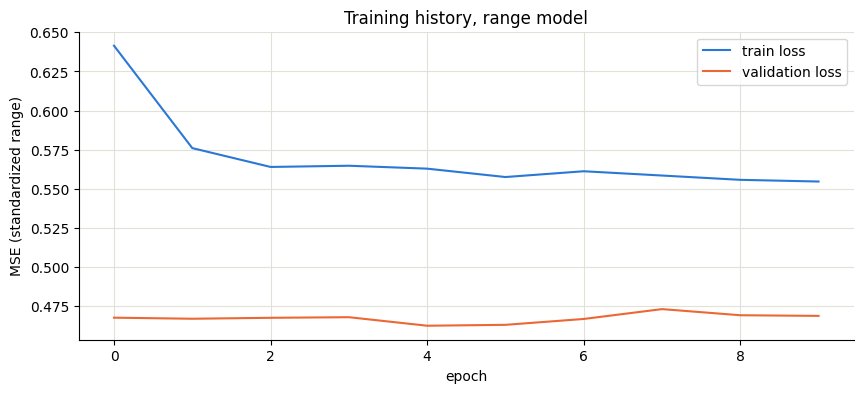

In [72]:
plt.plot(history_rng.history["loss"], color=c_nn, label="train loss")
plt.plot(history_rng.history["val_loss"], color=c_ar, label="validation loss")
plt.xlabel("epoch")
plt.ylabel("MSE (standardized range)")
plt.title("Training history, range model")
plt.legend()
plt.show()

In [73]:
pred_nn_rng = model_rng.predict(X_test_rng, verbose=0).reshape(len(tickers), -1).T
pred_nn_rng = pd.DataFrame(pred_nn_rng, index=test_days, columns=tickers)
pred_nn_rng = pred_nn_rng * rng_sd + rng_mu      # back to raw range

In [74]:
pred_nn_rng

,AAPL,AMZN,GOOGL,JNJ,JPM,KO,MSFT,NVDA,WMT,XOM
Date,,,,,,,,,,
2024-01-02,0.012632,0.016703,0.014448,0.010590,0.010986,0.009353,0.011945,0.022464,0.010511,0.015599
2024-01-03,0.020346,0.019963,0.016576,0.013734,0.013514,0.011413,0.015110,0.026447,0.010987,0.016864
2024-01-04,0.017471,0.021022,0.017201,0.013461,0.014017,0.011296,0.015142,0.025080,0.010477,0.017047
2024-01-05,0.018176,0.023611,0.019052,0.012583,0.015128,0.010861,0.014900,0.023441,0.010923,0.017186
2024-01-08,0.016708,0.020607,0.018050,0.011781,0.013876,0.010572,0.014794,0.024211,0.012337,0.015674
...,...,...,...,...,...,...,...,...,...,...
2026-11-16,0.018896,0.025360,0.025558,0.020025,0.014963,0.015927,0.025740,0.053094,0.018538,0.020971
2026-11-17,0.020698,0.029702,0.030304,0.021738,0.020203,0.016132,0.026579,0.056063,0.018342,0.022666
2026-11-18,0.019343,0.028015,0.029071,0.022168,0.024654,0.016121,0.029225,0.057400,0.018708,0.022115


In [75]:
actual_rng = rng[test_start:test_end]

mse_ar_rng = ((actual_rng - pred_ar_rng) ** 2).mean()
mse_nn_rng = ((actual_rng - pred_nn_rng) ** 2).mean()

results_rng = pd.DataFrame({"AR": mse_ar_rng / mse_avg, "NN": mse_nn_rng / mse_avg})

In [76]:
results_rng      # test MSE divided by the 20-day-average baseline MSE, below 1 beats the baseline

,AR,NN
Ticker,,
AAPL,0.761146,0.698829
AMZN,0.796774,0.744859
GOOGL,0.969668,0.923086
JNJ,0.936707,0.925694
JPM,0.884868,0.826357
KO,0.963096,0.932280
MSFT,0.861508,0.806731
NVDA,0.821210,0.770397
WMT,0.847123,0.828955


In [77]:
results_rng.mean()

AR    0.872801
NN    0.827925
dtype: float64

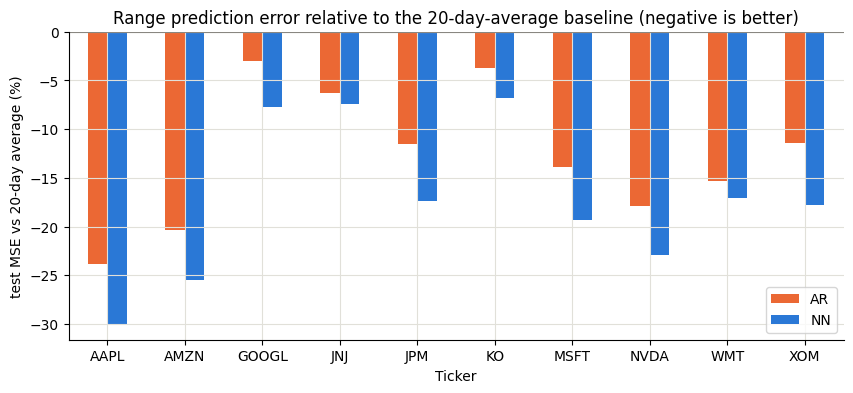

In [78]:
((results_rng - 1) * 100).plot.bar(color=[c_ar, c_nn], figsize=(10, 4))
plt.axhline(0, color=c_ref)
plt.ylabel("test MSE vs 20-day average (%)")
plt.title("Range prediction error relative to the 20-day-average baseline (negative is better)")
plt.xticks(rotation=0)
plt.show()

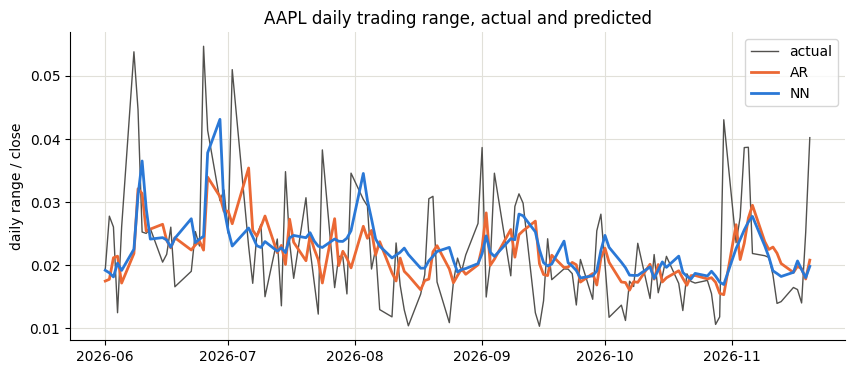

In [79]:
t = "AAPL"

plt.plot(actual_rng[t]["2026-06-01":], color=c_actual, linewidth=1, label="actual")
plt.plot(pred_ar_rng[t]["2026-06-01":], color=c_ar, linewidth=2, label="AR")
plt.plot(pred_nn_rng[t]["2026-06-01":], color=c_nn, linewidth=2, label="NN")
plt.ylabel("daily range / close")
plt.title("AAPL daily trading range, actual and predicted")
plt.legend()
plt.show()